<a href="https://colab.research.google.com/github/kumarsaurabh1817/Final-Computer-Vision-Training/blob/main/week3_detection/day2_yolo_custom_training/Week3_Day2_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 3 · Day 2 — Train YOLO on a Custom Dataset

**Goal:** fine-tune a COCO-pretrained YOLO26 detector on a real custom dataset, learn the annotation formats, validate labels visually, and report mAP on a held-out test split.

**Dataset:** [Hard Hat Workers on Kaggle](https://www.kaggle.com/datasets/andrewmvd/hard-hat-detection) — 5,000 construction-site images (416×416) with **Pascal VOC XML** boxes for `helmet`, `head`, and `person` (~1.2 GB). Converting VOC XML → YOLO TXT is part of today's lesson.

| Step | Output |
|---|---|
| Parse VOC XML, audit label quality | Class counts, box-size stats, bad-box report |
| Convert to YOLO format + 70/15/15 split | `dataset/images/{train,val,test}`, `dataset/labels/...`, `data.yaml` |
| Visual round-trip check | Labels re-drawn from the generated `.txt` files |
| Fine-tune YOLO26 | `best.pt`, training curves |
| Evaluate | mAP@0.5, mAP@0.5:0.95, per-class P/R/AP on **test**, recall by object size |

> Runtime: **T4 GPU**. A full run (`FULL_RUN=True`, 40 epochs, YOLO26s @ 640) takes roughly 30–45 min on a T4. Use `FULL_RUN=False` for a ~5 min smoke test; don't report smoke-test numbers.

## 0 · Install dependencies

In [1]:
import subprocess
import sys


def pip_install(*packages: str) -> None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])


pip_install("ultralytics==8.4.182", "kagglehub==1.0.2")

## 1 · Configuration

In [2]:
import json
import random
import shutil
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import matplotlib

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image
from ultralytics import YOLO

FULL_RUN = True
SEED = 42
MODEL_WEIGHTS = "yolo26s.pt"  # "yolo26n.pt" is ~2x faster; "yolo11s.pt" if YOLO26 is unavailable
EPOCHS = 40 if FULL_RUN else 3
IMGSZ = 640  # source images are 416px; upscaling helps the many small heads/helmets
BATCH = 16
PATIENCE = 15
MAX_IMAGES = None if FULL_RUN else 800  # subsample for smoke tests
SPLITS = {"train": 0.70, "val": 0.15, "test": 0.15}
CLASS_NAMES = ["helmet", "head", "person"]
SAVE_TO_DRIVE = False  # True -> copy best.pt to Google Drive so it survives the Colab session

IN_COLAB = "google.colab" in sys.modules
try:
    HERE = Path(__file__).resolve().parent
except NameError:
    HERE = Path.cwd()
OUTPUT_DIR = Path("/content/week3_outputs/day2") if IN_COLAB else HERE.parent / "results" / "day2"
DATA_DIR = Path("/content/datasets") if IN_COLAB else HERE.parent / "data"
YOLO_DATASET = DATA_DIR / "hardhat_yolo"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
random.seed(SEED)
np.random.seed(SEED)
print({"full_run": FULL_RUN, "model": MODEL_WEIGHTS, "epochs": EPOCHS, "imgsz": IMGSZ, "device": DEVICE})
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU — enable a T4 runtime, CPU training will be very slow.")


def save_fig(fig, name: str) -> None:
    path = OUTPUT_DIR / name
    fig.savefig(path, dpi=120, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)
    print(f"saved -> {path}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
{'full_run': True, 'model': 'yolo26s.pt', 'epochs': 40, 'imgsz': 640, 'device': 0}
GPU: Tesla T4


## 2 · Download from Kaggle and locate images + annotations

In [3]:
import kagglehub

KAGGLE_HANDLE = "andrewmvd/hard-hat-detection"
raw_root = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
print("Kaggle cache:", raw_root)

xml_files = sorted(raw_root.rglob("*.xml"))
image_files = {p.stem: p for ext in ("*.png", "*.jpg", "*.jpeg") for p in raw_root.rglob(ext)}
print(f"{len(xml_files)} XML annotation files | {len(image_files)} images")
assert xml_files and image_files, "Dataset layout not recognised — inspect raw_root"

100%|██████████| 1.22G/1.22G [00:18<00:00, 71.6MB/s]

Extracting files...


Kaggle cache: /root/.cache/kagglehub/datasets/andrewmvd/hard-hat-detection/versions/1
5000 XML annotation files | 5000 images


## 3 · Understand the source format: Pascal VOC XML

VOC stores **absolute pixel corners** (`xmin, ymin, xmax, ymax`) per object, one XML file per image. YOLO wants one `.txt` per image with **normalized centre format** `class cx cy w h`. Print one file to see the structure.

In [4]:
print(xml_files[0].read_text()[:900])


<annotation>
    <folder>images</folder>
    <filename>hard_hat_workers0.png</filename>
    <size>
        <width>416</width>
        <height>416</height>
        <depth>3</depth>
    </size>
    <segmented>0</segmented>
    <object>
        <name>helmet</name>
        <pose>Unspecified</pose>
        <truncated>0</truncated>
        <occluded>0</occluded>
        <difficult>0</difficult>
        <bndbox>
            <xmin>357</xmin>
            <ymin>116</ymin>
            <xmax>404</xmax>
            <ymax>175</ymax>
        </bndbox>
    </object>
    <object>
        <name>helmet</name>
        <pose>Unspecified</pose>
        <truncated>0</truncated>
        <occluded>0</occluded>
        <difficult>0</difficult>
        <bndbox>
            <xmin>4</xmin>
            <ymin>146</ymin>
            <xmax>39</xmax>
            <ymax>184</ymax>
        </bndbox>
    </object>
    <obje


In [5]:
def parse_voc(xml_path: Path) -> dict:
    root = ET.parse(xml_path).getroot()
    size = root.find("size")
    width = int(float(size.findtext("width", "0"))) if size is not None else 0
    height = int(float(size.findtext("height", "0"))) if size is not None else 0
    objects = []
    for obj in root.iter("object"):
        bb = obj.find("bndbox")
        objects.append(
            {
                "name": obj.findtext("name", "").strip().lower(),
                "box": [float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")],
            }
        )
    return {"stem": xml_path.stem, "width": width, "height": height, "objects": objects}


records = [parse_voc(p) for p in xml_files]
print(f"Parsed {len(records)} annotation files")

Parsed 5000 annotation files


## 4 · Audit label quality before training

Detection datasets live or die on annotation quality. Check: missing images, size mismatches between XML and the actual image, unknown classes, degenerate or out-of-bounds boxes.

Label audit:
  degenerate box < 2px (dropped)                     1

Class counts: {'helmet': 18965, 'head': 5785, 'person': 751}
Objects per image: mean=5.1, max=68


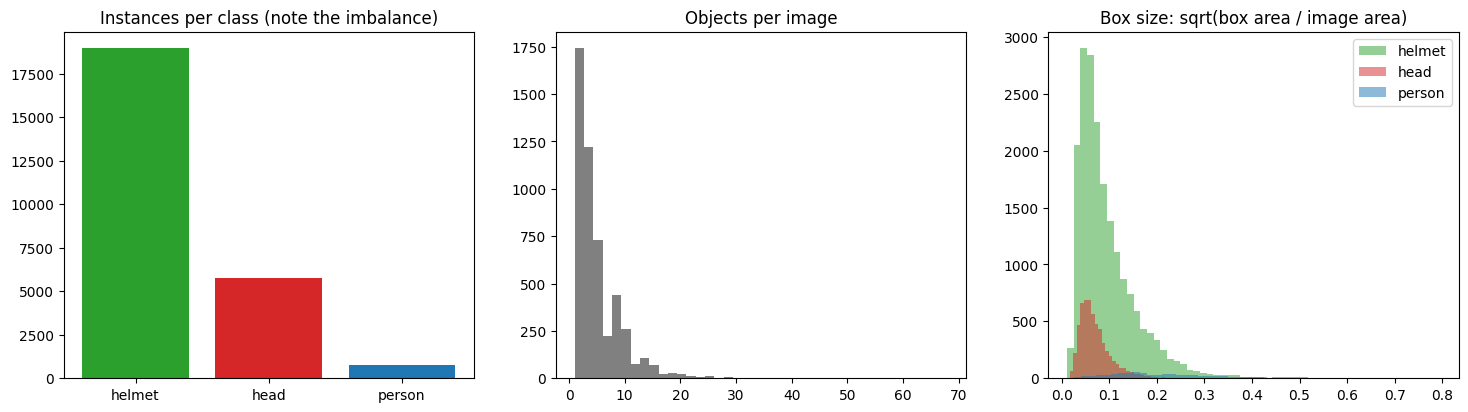

saved -> /content/week3_outputs/day2/day2_dataset_stats.png


In [6]:
issues = Counter()
class_counts = Counter()
rel_areas = {c: [] for c in CLASS_NAMES}
objects_per_image = []
clean_records = []

for rec in records:
    img_path = image_files.get(rec["stem"])
    if img_path is None:
        issues["missing image"] += 1
        continue
    with Image.open(img_path) as im:
        w, h = im.size
    if (rec["width"], rec["height"]) != (w, h):
        issues["XML size != image size (using real size)"] += 1
    kept = []
    for obj in rec["objects"]:
        if obj["name"] not in CLASS_NAMES:
            issues[f"unknown class '{obj['name']}'"] += 1
            continue
        x1, y1, x2, y2 = obj["box"]
        if x1 < 0 or y1 < 0 or x2 > w or y2 > h:
            issues["box outside image (clipped)"] += 1
        x1, x2 = np.clip([x1, x2], 0, w)
        y1, y2 = np.clip([y1, y2], 0, h)
        if (x2 - x1) < 2 or (y2 - y1) < 2:
            issues["degenerate box < 2px (dropped)"] += 1
            continue
        kept.append({"name": obj["name"], "box": [x1, y1, x2, y2]})
        class_counts[obj["name"]] += 1
        rel_areas[obj["name"]].append((x2 - x1) * (y2 - y1) / (w * h))
    if not kept:
        issues["image with no valid objects (kept as background)"] += 1
    objects_per_image.append(len(kept))
    clean_records.append({"stem": rec["stem"], "image": img_path, "width": w, "height": h, "objects": kept})

print("Label audit:")
for k, v in issues.most_common():
    print(f"  {k:<50} {v}")
print("\nClass counts:", dict(class_counts))
print(f"Objects per image: mean={np.mean(objects_per_image):.1f}, max={np.max(objects_per_image)}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].bar(CLASS_NAMES, [class_counts[c] for c in CLASS_NAMES], color=["tab:green", "tab:red", "tab:blue"])
axes[0].set_title("Instances per class (note the imbalance)")
axes[1].hist(objects_per_image, bins=40, color="gray")
axes[1].set_title("Objects per image")
for c, color in zip(CLASS_NAMES, ["tab:green", "tab:red", "tab:blue"]):
    if rel_areas[c]:
        axes[2].hist(np.sqrt(rel_areas[c]), bins=50, alpha=0.5, label=c, color=color)
axes[2].set_title("Box size: sqrt(box area / image area)")
axes[2].legend()
save_fig(fig, "day2_dataset_stats.png")

## 5 · Convert VOC → YOLO and split train / val / test

YOLO label line: `class_id cx cy w h`, all divided by image width/height. Ultralytics finds a label by swapping `/images/` for `/labels/` in the image path, so both trees must mirror each other.

In [7]:
def voc_box_to_yolo(box, w, h) -> list[float]:
    x1, y1, x2, y2 = box
    return [(x1 + x2) / 2 / w, (y1 + y2) / 2 / h, (x2 - x1) / w, (y2 - y1) / h]


selected = list(clean_records)
random.Random(SEED).shuffle(selected)
if MAX_IMAGES:
    selected = selected[:MAX_IMAGES]

n = len(selected)
n_train = int(n * SPLITS["train"])
n_val = int(n * SPLITS["val"])
split_records = {
    "train": selected[:n_train],
    "val": selected[n_train : n_train + n_val],
    "test": selected[n_train + n_val :],
}

if YOLO_DATASET.exists():
    shutil.rmtree(YOLO_DATASET)  # rebuild so config changes always take effect
for split, recs in split_records.items():
    img_dir = YOLO_DATASET / "images" / split
    lbl_dir = YOLO_DATASET / "labels" / split
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)
    for rec in recs:
        shutil.copy2(rec["image"], img_dir / rec["image"].name)
        lines = [
            f"{CLASS_NAMES.index(o['name'])} " + " ".join(f"{v:.6f}" for v in voc_box_to_yolo(o["box"], rec["width"], rec["height"]))
            for o in rec["objects"]
        ]
        (lbl_dir / f"{rec['image'].stem}.txt").write_text("\n".join(lines))

split_class_counts = {
    split: Counter(o["name"] for r in recs for o in r["objects"]) for split, recs in split_records.items()
}
print(pd.DataFrame(split_class_counts).T.assign(images={s: len(r) for s, r in split_records.items()}))

DATA_YAML = YOLO_DATASET / "data.yaml"
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(
        {"path": str(YOLO_DATASET), "train": "images/train", "val": "images/val", "test": "images/test",
         "names": {i: c for i, c in enumerate(CLASS_NAMES)}},
        f,
        sort_keys=False,
    )
print(DATA_YAML.read_text())
print("Example label file:\n", next((YOLO_DATASET / "labels" / "train").glob("*.txt")).read_text()[:300])

       helmet  head  person  images
train   13422  4055     475    3500
val      2762   831     198     750
test     2781   899      78     750
path: /content/datasets/hardhat_yolo
train: images/train
val: images/val
test: images/test
names:
  0: helmet
  1: head
  2: person

Example label file:
 0 0.104567 0.326506 0.045673 0.055422
0 0.295673 0.327711 0.057692 0.067470
0 0.566106 0.308434 0.064904 0.048193
0 0.853365 0.213253 0.072115 0.069880


## 6 · Visual round-trip check: draw boxes **from the generated YOLO files**

If boxes are shifted, too large, or on the wrong objects here, the conversion is wrong. Fix it now; the model cannot learn around broken labels.

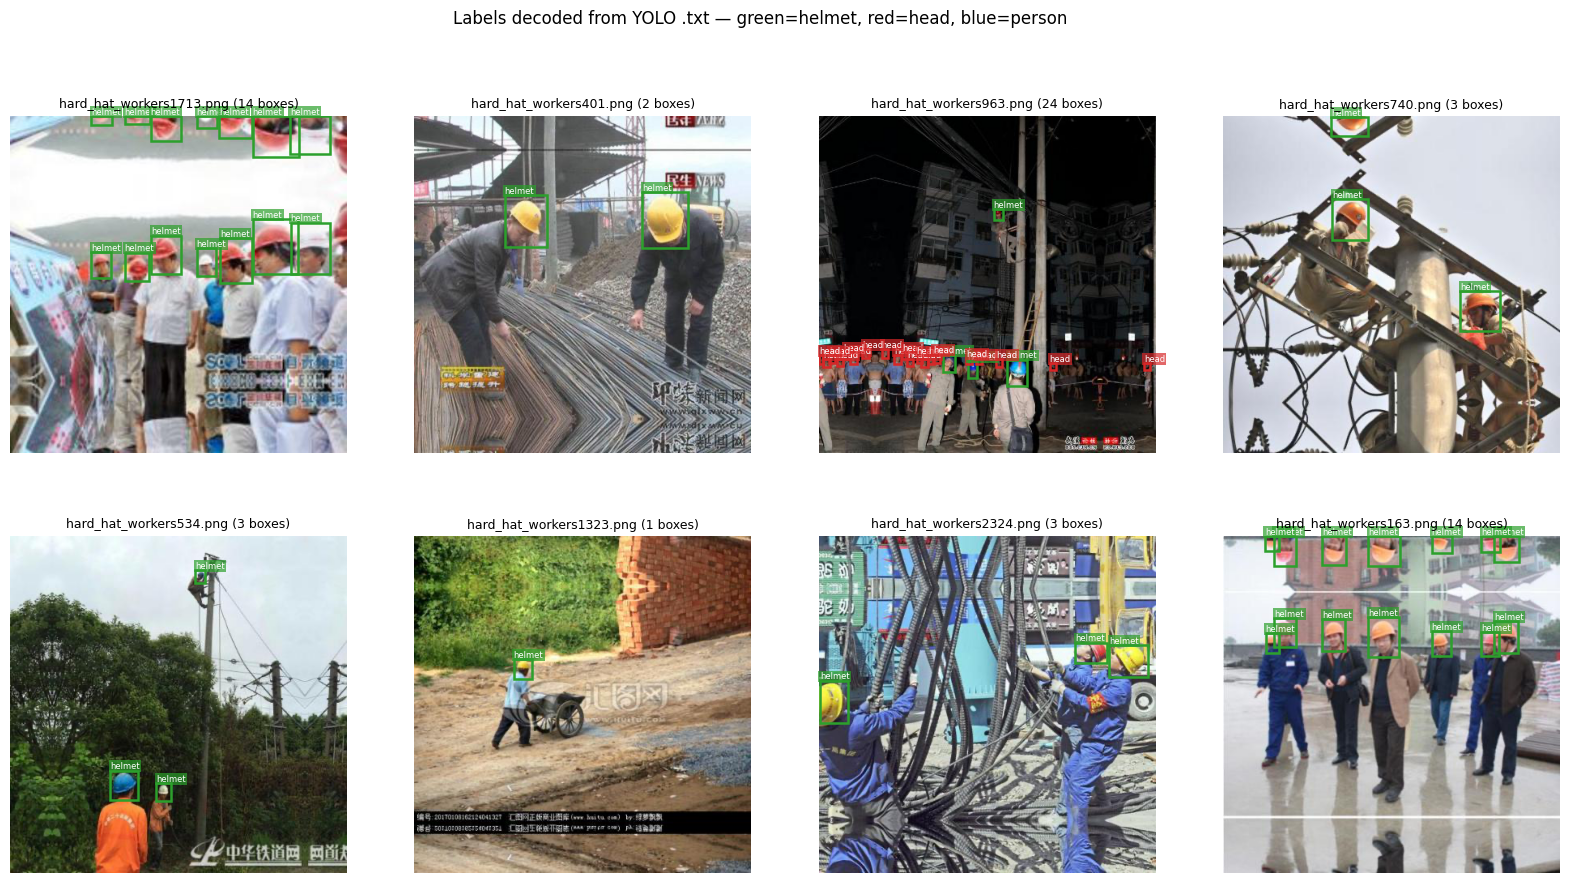

saved -> /content/week3_outputs/day2/day2_label_roundtrip_check.png


In [8]:
COLORS = {"helmet": "tab:green", "head": "tab:red", "person": "tab:blue"}


def read_yolo_label(label_path: Path, w: int, h: int):
    if not label_path.exists() or label_path.stat().st_size == 0:
        return np.zeros(0, dtype=int), np.zeros((0, 4))
    rows = np.loadtxt(label_path, ndmin=2)
    cx, cy, bw, bh = rows[:, 1] * w, rows[:, 2] * h, rows[:, 3] * w, rows[:, 4] * h
    return rows[:, 0].astype(int), np.stack([cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2], axis=1)


def draw(ax, boxes, labels, scores=None):
    for i, (b, lab) in enumerate(zip(boxes, labels)):
        color = COLORS[lab]
        ax.add_patch(patches.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False, lw=1.8, ec=color))
        txt = lab if scores is None else f"{lab} {scores[i]:.2f}"
        ax.text(b[0], b[1] - 2, txt, fontsize=6, color="white", bbox=dict(facecolor=color, alpha=0.7, pad=1, lw=0))


check_imgs = random.Random(1).sample(sorted((YOLO_DATASET / "images" / "train").iterdir()), 8)
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, img_path in zip(axes.flat, check_imgs):
    img = Image.open(img_path).convert("RGB")
    cls, boxes = read_yolo_label(YOLO_DATASET / "labels" / "train" / f"{img_path.stem}.txt", *img.size)
    ax.imshow(img)
    draw(ax, boxes, [CLASS_NAMES[c] for c in cls])
    ax.set_title(f"{img_path.name} ({len(cls)} boxes)", fontsize=9)
    ax.axis("off")
fig.suptitle("Labels decoded from YOLO .txt — green=helmet, red=head, blue=person")
save_fig(fig, "day2_label_roundtrip_check.png")

## 7 · Fine-tune YOLO26

Starting from COCO weights is transfer learning (Week 2) applied to detection: the backbone already knows edges, textures, and people, so only the head and higher layers need to adapt. Ultralytics handles mosaic augmentation, warm-up, the LR schedule, and EMA weights. `patience` stops early if val mAP stalls.

In [9]:
model = YOLO(MODEL_WEIGHTS)
train_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=PATIENCE,
    seed=SEED,
    deterministic=True,
    workers=2,
    device=DEVICE,
    project=str(OUTPUT_DIR),
    name="hardhat_train",
    exist_ok=True,
    plots=True,
)
RUN_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
print("Run dir:", RUN_DIR)
print("Best weights:", BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.182 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/hardhat_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.p

## 8 · Training curves

Healthy run: train and val losses fall together, and val mAP rises then plateaus. A val loss that climbs while train loss keeps falling means overfitting.

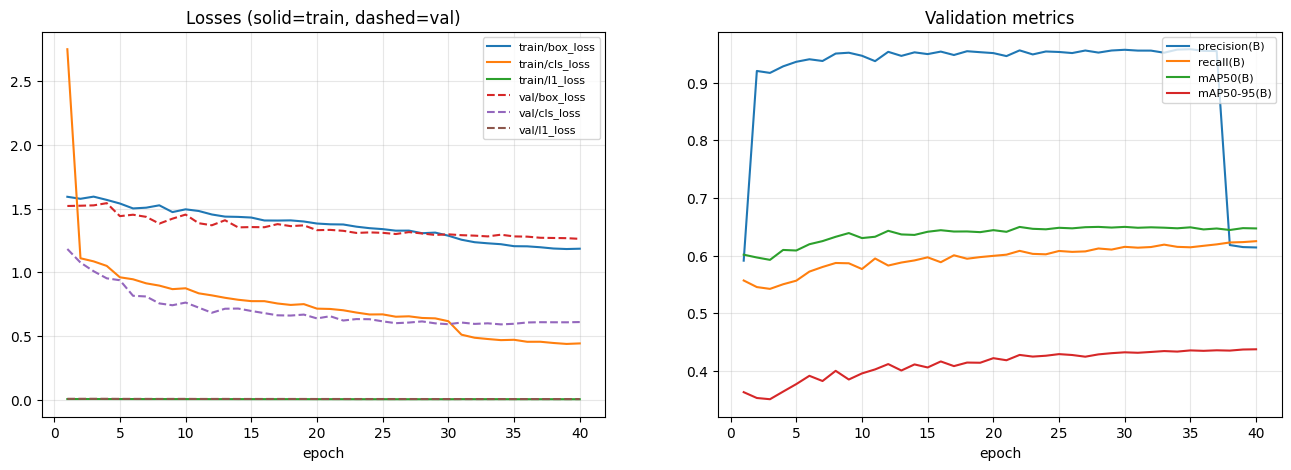

saved -> /content/week3_outputs/day2/day2_training_curves.png


In [10]:
history = pd.read_csv(RUN_DIR / "results.csv")
history.columns = [c.strip() for c in history.columns]
loss_cols = [c for c in history.columns if c.endswith("_loss")]
metric_cols = [c for c in history.columns if c.startswith("metrics/")]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for c in loss_cols:
    axes[0].plot(history["epoch"], history[c], label=c, ls="-" if c.startswith("train") else "--")
axes[0].set_title("Losses (solid=train, dashed=val)")
axes[0].set_xlabel("epoch")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
for c in metric_cols:
    axes[1].plot(history["epoch"], history[c], label=c.replace("metrics/", ""))
axes[1].set_title("Validation metrics")
axes[1].set_xlabel("epoch")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
save_fig(fig, "day2_training_curves.png")

## 9 · Evaluate on val and the untouched test split

In [11]:
best_model = YOLO(str(BEST_WEIGHTS))


def evaluate(split: str):
    metrics = best_model.val(
        data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, plots=True,
        project=str(OUTPUT_DIR), name=f"eval_{split}", exist_ok=True, verbose=False,
    )
    rows = []
    for i, c in enumerate(metrics.box.ap_class_index):
        p, r, ap50, ap = metrics.box.class_result(i)
        rows.append({"split": split, "class": CLASS_NAMES[int(c)], "instances": split_class_counts[split][CLASS_NAMES[int(c)]],
                     "precision": p, "recall": r, "AP50": ap50, "AP50-95": ap})
    rows.append({"split": split, "class": "ALL", "instances": sum(split_class_counts[split].values()),
                 "precision": metrics.box.mp, "recall": metrics.box.mr, "AP50": metrics.box.map50, "AP50-95": metrics.box.map})
    return metrics, pd.DataFrame(rows)


val_metrics, val_table = evaluate("val")
test_metrics, test_table = evaluate("test")
results_table = pd.concat([val_table, test_table], ignore_index=True)
print(results_table.round(3).to_string(index=False))
results_table.to_csv(OUTPUT_DIR / "day2_metrics.csv", index=False)

Ultralytics 8.4.182 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,466,341 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3861.8±916.4 MB/s, size: 240.8 KB)
val: Scanning /content/datasets/hardhat_yolo/labels/val.cache... 750 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 750/750 224.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 47/47 3.2it/s 14.9s
                   all        750       3791      0.614      0.625      0.647      0.438
Speed: 1.5ms preprocess, 12.5ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/week3_outputs/day2/eval_val
Ultralytics 8.4.182 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,466,341 parameters, 0 gradients, 20.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 36.1±14.8 MB

### Ultralytics evaluation plots (test split)

The **normalized confusion matrix** shows which classes get confused (`head` ↔ `helmet` is the interesting pair) and how often objects are missed entirely (the `background` column).

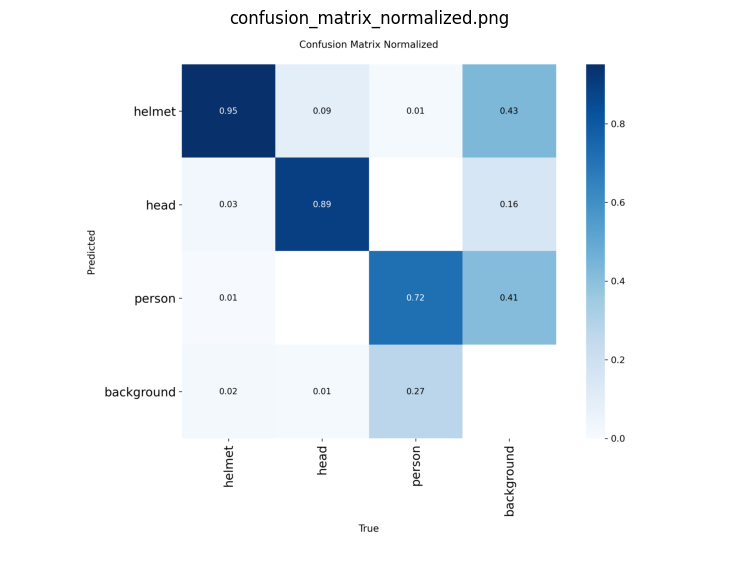

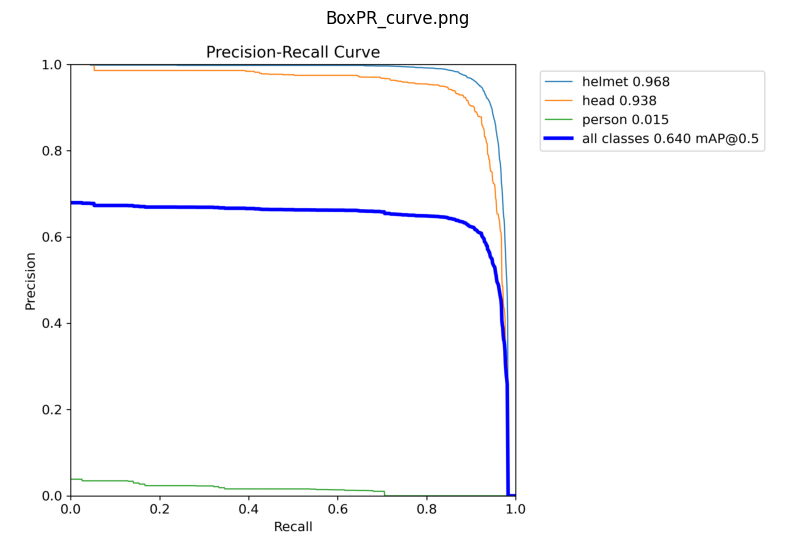

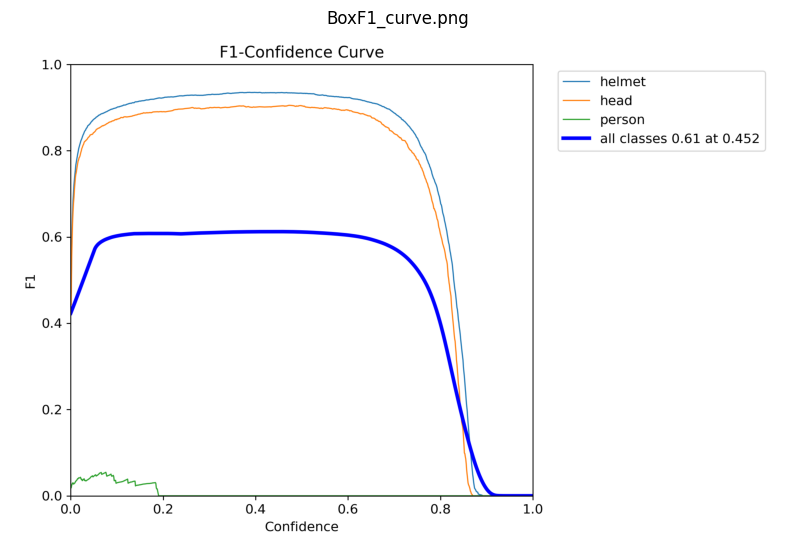

Plots in /content/week3_outputs/day2/eval_test : ['confusion_matrix_normalized.png', 'BoxPR_curve.png', 'BoxF1_curve.png']


In [12]:
eval_dir = OUTPUT_DIR / "eval_test"
plot_names = ["confusion_matrix_normalized.png", "BoxPR_curve.png", "PR_curve.png", "BoxF1_curve.png", "F1_curve.png"]
found = [eval_dir / n for n in plot_names if (eval_dir / n).exists()]
for path in found:
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(Image.open(path))
    ax.set_title(path.name)
    ax.axis("off")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)
print("Plots in", eval_dir, ":", [p.name for p in found])

## 10 · Qualitative check: ground truth vs predictions on test images

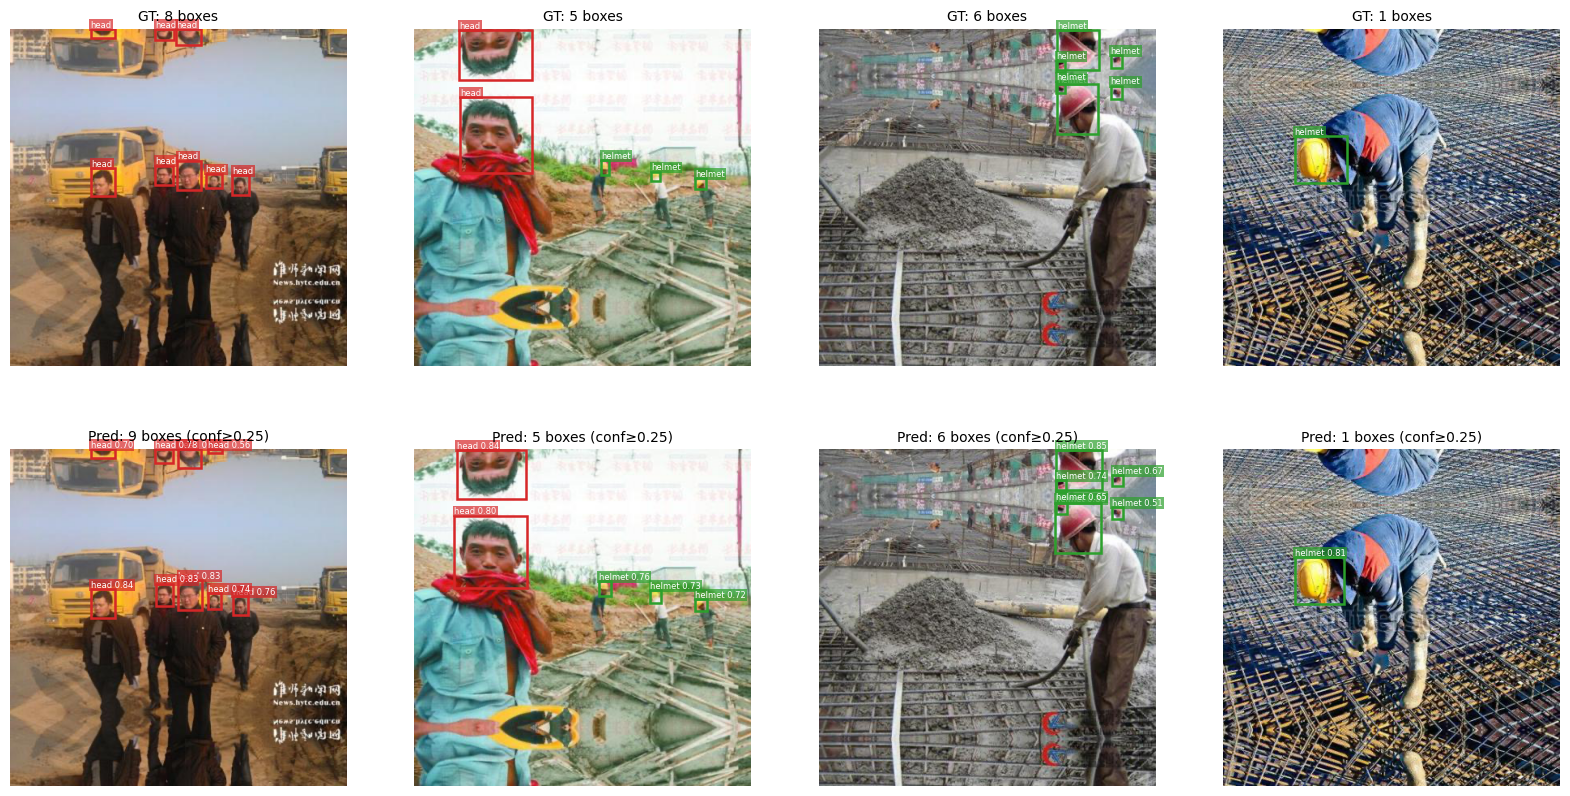

saved -> /content/week3_outputs/day2/day2_test_predictions.png


In [13]:
test_imgs = sorted((YOLO_DATASET / "images" / "test").iterdir())
show_imgs = random.Random(7).sample(test_imgs, 4)
preds = best_model.predict([str(p) for p in show_imgs], conf=0.25, imgsz=IMGSZ, device=DEVICE, verbose=False)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for col, (img_path, res) in enumerate(zip(show_imgs, preds)):
    img = Image.open(img_path).convert("RGB")
    cls, boxes = read_yolo_label(YOLO_DATASET / "labels" / "test" / f"{img_path.stem}.txt", *img.size)
    axes[0, col].imshow(img)
    draw(axes[0, col], boxes, [CLASS_NAMES[c] for c in cls])
    axes[0, col].set_title(f"GT: {len(cls)} boxes", fontsize=10)
    axes[1, col].imshow(img)
    draw(axes[1, col], res.boxes.xyxy.cpu().numpy(), [CLASS_NAMES[int(c)] for c in res.boxes.cls], res.boxes.conf.cpu().numpy())
    axes[1, col].set_title(f"Pred: {len(res.boxes)} boxes (conf≥0.25)", fontsize=10)
    for ax in axes[:, col]:
        ax.axis("off")
save_fig(fig, "day2_test_predictions.png")

## 11 · Error analysis: recall by object size

COCO buckets: small < 32² px, medium < 96² px, large ≥ 96² px (measured on the original 416×416 image). Small objects are usually where a detector loses most recall — that motivates larger `imgsz`, tiling (SAHI), or a bigger model.

In [14]:
def pairwise_iou(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    tl = np.maximum(a[:, None, :2], b[None, :, :2])
    br = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.prod(np.clip(br - tl, 0, None), axis=2)
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / np.maximum(area(a)[:, None] + area(b)[None, :] - inter, 1e-9)


def matched_gt(pred_boxes, pred_scores, gt_boxes, thr=0.5) -> np.ndarray:
    """Greedy score-ordered matching; returns a hit flag per ground-truth box."""
    hit = np.zeros(len(gt_boxes), dtype=bool)
    if len(pred_boxes) == 0 or len(gt_boxes) == 0:
        return hit
    ious = pairwise_iou(pred_boxes, gt_boxes)
    for i in np.argsort(-pred_scores):
        cand = np.where(~hit & (ious[i] >= thr))[0]
        if cand.size:
            hit[cand[np.argmax(ious[i, cand])]] = True
    return hit


size_rows = []
for start in range(0, len(test_imgs), 64):
    batch_paths = test_imgs[start : start + 64]
    for img_path, res in zip(batch_paths, best_model.predict([str(p) for p in batch_paths], conf=0.25, imgsz=IMGSZ, device=DEVICE, verbose=False)):
        w, h = res.orig_shape[1], res.orig_shape[0]
        g_cls, g_boxes = read_yolo_label(YOLO_DATASET / "labels" / "test" / f"{img_path.stem}.txt", w, h)
        p_cls = res.boxes.cls.cpu().numpy().astype(int)
        p_boxes, p_scores = res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy()
        for c in range(len(CLASS_NAMES)):
            gm = g_cls == c
            hits = matched_gt(p_boxes[p_cls == c], p_scores[p_cls == c], g_boxes[gm])
            areas = (g_boxes[gm, 2] - g_boxes[gm, 0]) * (g_boxes[gm, 3] - g_boxes[gm, 1])
            for a, hit in zip(areas, hits):
                bucket = "small" if a < 32**2 else "medium" if a < 96**2 else "large"
                size_rows.append({"class": CLASS_NAMES[c], "size": bucket, "hit": hit})

size_df = pd.DataFrame(size_rows)
size_table = size_df.pivot_table(index="class", columns="size", values="hit", aggfunc=["mean", "count"])
print("Recall@IoU0.5 (conf≥0.25) by object size:")
print(size_table.round(3))
size_table.to_csv(OUTPUT_DIR / "day2_recall_by_size.csv")

Recall@IoU0.5 (conf≥0.25) by object size:
         mean               count             
size    large medium  small large medium small
class                                         
head    0.000  0.974  0.895     1    305   593
helmet  0.989  0.969  0.920    90   1187  1504
person  0.000  0.000  0.000    38     37     3


## 12 · Save artifacts

In [15]:
final_weights = OUTPUT_DIR / "hardhat_best.pt"
shutil.copy2(BEST_WEIGHTS, final_weights)

test_all = test_table[test_table["class"] == "ALL"].iloc[0]
summary = {
    "dataset": "andrewmvd/hard-hat-detection (Kaggle)",
    "model": MODEL_WEIGHTS,
    "epochs_requested": EPOCHS,
    "epochs_run": int(history["epoch"].max()),
    "imgsz": IMGSZ,
    "images_per_split": {s: len(r) for s, r in split_records.items()},
    "test": {"mAP50": float(test_all["AP50"]), "mAP50_95": float(test_all["AP50-95"]),
             "precision": float(test_all["precision"]), "recall": float(test_all["recall"])},
    "per_class_test": test_table[test_table["class"] != "ALL"].round(4).to_dict(orient="records"),
    "full_run": FULL_RUN,
    "weights": str(final_weights),
}
with open(OUTPUT_DIR / "day2_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)
print(json.dumps(summary, indent=2, default=float))

if SAVE_TO_DRIVE and IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    drive_dir = Path("/content/drive/MyDrive/cv_week3")
    drive_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(final_weights, drive_dir / final_weights.name)
    print("Copied weights to", drive_dir)

{
  "dataset": "andrewmvd/hard-hat-detection (Kaggle)",
  "model": "yolo26s.pt",
  "epochs_requested": 40,
  "epochs_run": 40,
  "imgsz": 640,
  "images_per_split": {
    "train": 3500,
    "val": 750,
    "test": 750
  },
  "test": {
    "mAP50": 0.6402725330283466,
    "mAP50_95": 0.42398716633045136,
    "precision": 0.9572953377271526,
    "recall": 0.6019453474014637
  },
  "per_class_test": [
    {
      "split": "test",
      "class": "helmet",
      "instances": 2781,
      "precision": 0.9576,
      "recall": 0.9126,
      "AP50": 0.968,
      "AP50-95": 0.6403
    },
    {
      "split": "test",
      "class": "head",
      "instances": 899,
      "precision": 0.9143,
      "recall": 0.8932,
      "AP50": 0.9377,
      "AP50-95": 0.6235
    },
    {
      "split": "test",
      "class": "person",
      "instances": 78,
      "precision": 1.0,
      "recall": 0.0,
      "AP50": 0.0151,
      "AP50-95": 0.0081
    }
  ],
  "full_run": true,
  "weights": "/content/week3_outputs/

## Takeaways (fill in with your numbers)

- Test mAP@0.5 = ___, mAP@0.5:0.95 = ___ on ___ test images.
- Strongest / weakest class: ___ / ___. Is the weakest class also the rarest? (Compare with the instance counts.)
- Small-object recall vs large-object recall: ___ vs ___.
- What would you try next? Larger model, higher `imgsz`, more epochs, class re-weighting, or fixing labels found in the audit.

Next: Day 3 moves from boxes to pixel masks (segmentation).